CSV file created successfully!
File name: sales_data.csv

First five rows:
        Date Product  Sales  Quantity Region
0 2023-01-01       A    200         4  North
1 2023-01-02       B    150         3  South
2 2023-01-03       A    220         5  North
3 2023-01-04       C    300         6   East
4 2023-01-05       B    180         4   West

Missing values:
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64

Summary statistics:
            Sales  Quantity
count   12.000000  12.00000
mean   243.333333   5.25000
std     66.923747   1.76455
min    150.000000   3.00000
25%    187.500000   4.00000
50%    235.000000   5.00000
75%    302.500000   6.25000
max    340.000000   8.00000

Product-wise sales:
  Product  Sales  Quantity
0       A    950        20
1       B    690        14
2       C   1280        29


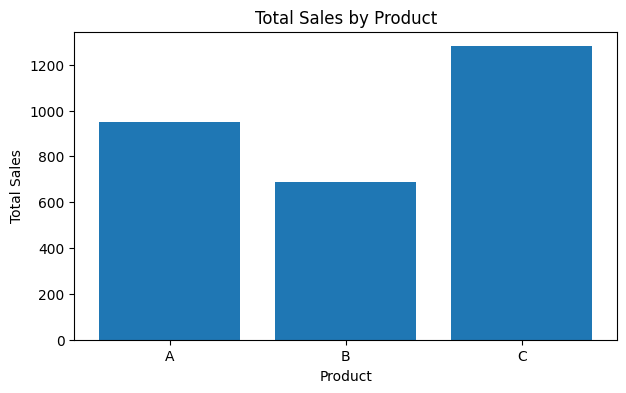

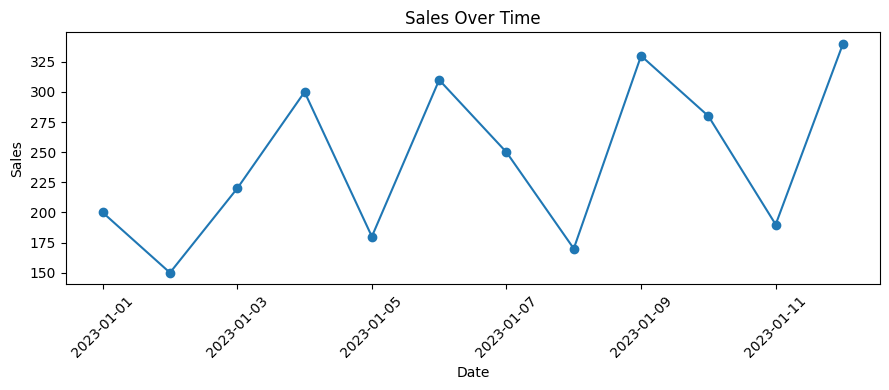


Sales by region and product:
Product    A    B     C
Region                 
East       0    0  1280
North    950    0     0
South      0  320     0
West       0  370     0

Correlation matrix:
            Sales  Quantity
Sales     1.00000   0.97768
Quantity  0.97768   1.00000


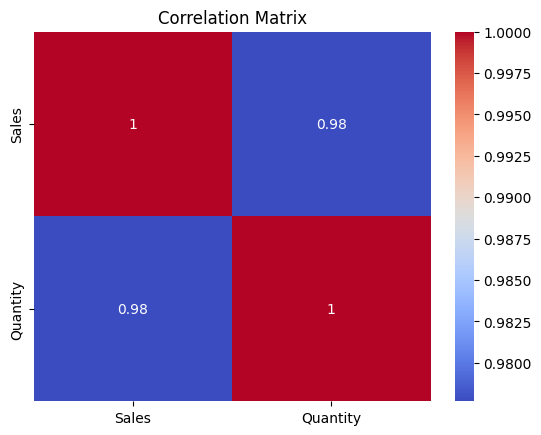

In [5]:

# EXPERIMENT 2: CSV Data Analysis, Preprocessing and Visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create the CSV file automatically
data = {
    "Date": pd.date_range("2023-01-01", periods=12, freq="D"),
    "Product": ["A", "B", "A", "C", "B", "C",
                "A", "B", "C", "A", "B", "C"],
    "Sales": [200, 150, 220, 300, 180, 310,
              250, 170, 330, 280, 190, 340],
    "Quantity": [4, 3, 5, 6, 4, 7, 5, 3, 8, 6, 4, 8],
    "Region": ["North", "South", "North", "East", "West",
               "East", "North", "South", "East", "North",
               "West", "East"]
}

df = pd.DataFrame(data)
df.to_csv("sales_data.csv", index=False)

print("CSV file created successfully!")
print("File name: sales_data.csv")

# Step 2: Read the CSV file
df = pd.read_csv("sales_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

print("\nFirst five rows:")
print(df.head())

# Step 3: Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Step 4: Preprocess the data
df["Sales"] = df["Sales"].fillna(df["Sales"].mean())
df = df.dropna(subset=["Product", "Quantity", "Region"])

# Step 5: Display summary statistics
print("\nSummary statistics:")
print(df[["Sales", "Quantity"]].describe())

# Step 6: Group sales by product
product_summary = df.groupby("Product", as_index=False).agg(
    Sales=("Sales", "sum"),
    Quantity=("Quantity", "sum")
)

print("\nProduct-wise sales:")
print(product_summary)

# Step 7: Bar chart
plt.figure(figsize=(7, 4))
plt.bar(product_summary["Product"], product_summary["Sales"])
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product")
plt.show()

# Step 8: Sales over time
sales_over_time = df.groupby("Date", as_index=False)["Sales"].sum()

plt.figure(figsize=(9, 4))
plt.plot(sales_over_time["Date"], sales_over_time["Sales"], marker="o")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 9: Sales by region and product
print("\nSales by region and product:")
print(df.pivot_table(
    values="Sales",
    index="Region",
    columns="Product",
    aggfunc="sum",
    fill_value=0
))

# Step 10: Correlation matrix
correlation = df[["Sales", "Quantity"]].corr()

print("\nCorrelation matrix:")
print(correlation)

sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()
